| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_2_Heun.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_4_Runge_Kutta.ipynb) |

# 7.3 Midpoint: evaluar la dinámica en el centro del paso

El punto medio explícito usa un predictor de medio paso para obtener una pendiente representativa del intervalo. Tiene orden dos como Heun, pero se comporta distinto en ecuaciones no lineales. Distinguiremos cuidadosamente su versión explícita de la implícita y su relación con conservación geométrica.

Los experimentos son autocontenidos y rápidos en CPU. Requisitos: derivadas, integrales, ecuaciones diferenciales ordinarias y errores numéricos. Ejecuta todas las celdas en orden. La solución exacta se usa como control cuando está disponible; en otros casos se compara contra una solución de referencia más precisa.

## 1. Problema de valor inicial y notación

Un problema de valor inicial tiene forma
$$y'(t)=f(t,y(t)),\qquad y(t_0)=y_0.$$
El estado $y$ puede ser un número o un vector. La función $f$ expresa la ley física y sus unidades son unidades de estado por unidades de tiempo. Bajo continuidad en $t$ y una condición local de Lipschitz en $y$, existe una solución única local; una implementación numérica no reemplaza estos supuestos.

Usaremos una malla $t_n=t_0+nh$ y una aproximación $y_n\approx y(t_n)$. Es esencial distinguir una evaluación de pendiente $f(t_n,y_n)$ de una actualización del estado. Para enfriamiento $y'=-ky$, el coeficiente $k>0$ tiene unidades de inverso del tiempo y la solución exacta es $y_0e^{-kt}$.

Un simulador introduce error de discretización además del error del modelo. Si una red se entrena con sus trayectorias, puede aprender ambas cosas. Por ello se estudian refinamiento, estabilidad y coste antes de usar los resultados como datos científicos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4), "axes.grid":True, "font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Fórmula y motivación por cuadratura

Aplicar punto medio a la integral exacta sugeriría $y(t+h)=y(t)+hf(t+h/2,y(t+h/2))$. Aproximamos el estado del centro con medio paso de Euler:
$$k_1=f(t_n,y_n),\qquad y_{\rm mid}=y_n+\frac h2k_1,$$
$$k_2=f(t_n+h/2,y_{\rm mid}),\qquad\boxed{y_{n+1}=y_n+h k_2}.$$
La primera pendiente solo construye un estado intermedio; la actualización final usa exclusivamente la segunda. Esto requiere dos evaluaciones por paso. Para un campo constante, reproduce exactamente una recta.

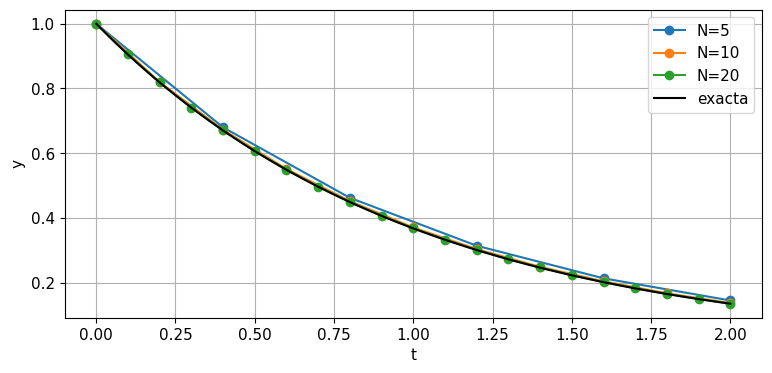

In [2]:
def midpoint(fun,tspan,y0,n):
    t=np.linspace(*tspan,n+1); h=t[1]-t[0]
    y=np.empty((n+1,np.atleast_1d(y0).size)); y[0]=np.atleast_1d(y0)
    for j in range(n):
        k1=np.asarray(fun(t[j],y[j]))
        k2=np.asarray(fun(t[j]+h/2,y[j]+h*k1/2))
        y[j+1]=y[j]+h*k2
    return t,y

q=np.linspace(0,2,500)
for n in [5,10,20]:
    t,y=midpoint(lambda t,y:-y,(0,2),1.,n)
    plt.plot(t,y[:,0],"o-",label=f"N={n}")
plt.plot(q,np.exp(-q),"k",label="exacta")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()

**Interpretación.** Para esta ecuación lineal, midpoint y Heun producen exactamente el mismo factor $1-h+h^2/2$. No pueden distinguirse únicamente con este ejemplo.

## 3. Orden dos por Taylor

Expandimos la pendiente del centro:
$$f(t+h/2,y+hf/2)=f+\frac h2f_t+\frac h2f_yf+O(h^2).$$
Al multiplicar por $h$, aparecen los mismos términos de Taylor de la solución hasta segundo orden. Así, el defecto local no normalizado es $O(h^3)$ y el global $O(h^2)$.

La tabla de Butcher tiene $c=(0,1/2)$, $A_{21}=1/2$ y $b=(0,1)$. Las condiciones $\sum b_i=1$ y $\sum b_i c_i=1/2$ explican la exactitud de primer y segundo orden; para órdenes mayores se necesitan más condiciones.

Órdenes: [2.116611 2.056157 2.027558 2.013651]


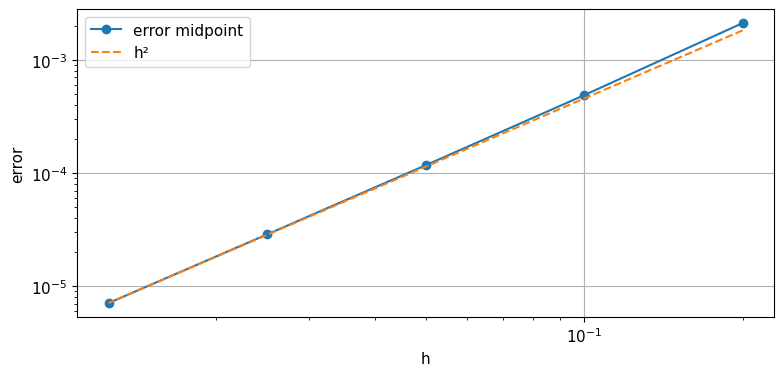

In [3]:
ns=np.array([10,20,40,80,160]); errors=[]
for n in ns:
    _,y=midpoint(lambda t,y:-y,(0,2),1.,n)
    errors.append(abs(y[-1,0]-np.exp(-2)))
errors=np.array(errors)
print("Órdenes:",np.log2(errors[:-1]/errors[1:]))
plt.loglog(2/ns,errors,"o-",label="error midpoint")
plt.loglog(2/ns,errors[-1]*(ns[-1]/ns)**2,"--",label="h²")
plt.xlabel("h"); plt.ylabel("error"); plt.legend(); plt.show()

**Interpretación.** La pendiente cercana a dos confirma el comportamiento esperado en este régimen. Para estudiar diferencias entre métodos de orden dos, una ecuación no lineal es más informativa que un decaimiento lineal.

## 4. Midpoint y Heun en una ecuación no lineal

La ecuación $y'=y^2$, $y(0)=1$ tiene solución $y=1/(1-t)$ y explota en $t=1$. Integramos solo hasta $T=0.7$, donde sigue siendo suave. Para un paso,
$$y_{n+1}^{\rm mid}=y_n+h(y_n+h y_n^2/2)^2.$$
Heun promedia $y_n^2$ y $(y_n+hy_n^2)^2$, por lo que sus términos de orden tres difieren. Mismo orden global no implica mismas constantes de error.

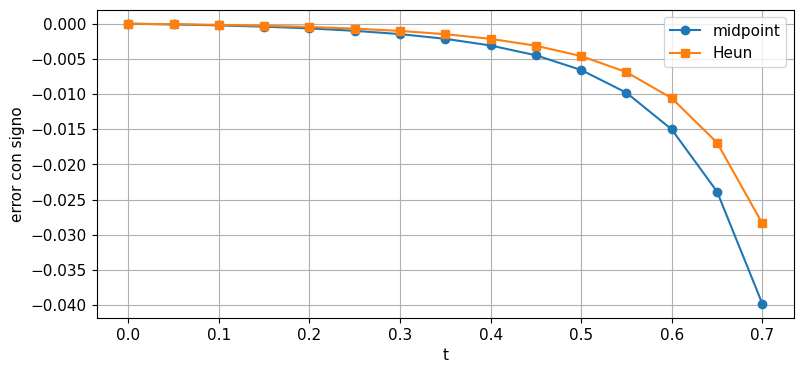

In [4]:
def heun_scalar(fun,tspan,y0,n):
    t=np.linspace(*tspan,n+1); h=t[1]-t[0]; y=np.empty(n+1); y[0]=y0
    for j in range(n):
        k1=fun(t[j],y[j]); k2=fun(t[j+1],y[j]+h*k1)
        y[j+1]=y[j]+h*(k1+k2)/2
    return t,y

t,ym=midpoint(lambda t,y:y*y,(0,0.7),1.,14)
_,yh=heun_scalar(lambda t,y:y*y,(0,0.7),1.,14)
plt.plot(t,ym[:,0]-1/(1-t),"o-",label="midpoint")
plt.plot(t,yh-1/(1-t),"s-",label="Heun")
plt.xlabel("t"); plt.ylabel("error con signo"); plt.legend(); plt.show()

**Interpretación.** Las trayectorias tienen errores distintos aunque ambas fórmulas sean de orden dos. Acercarse a la explosión vuelve grandes las derivadas superiores, así que un paso adecuado temprano puede resultar insuficiente más tarde.

## 5. Forzamiento temporal y punto medio exacto

Para $y'=t$, el método evalúa la pendiente en $t+h/2$, y la regla de punto medio integra exactamente esa función lineal. Para $y'=t^2$, ya aparece error. Esta comparación permite comprobar las abscisas temporales sin mezclar no linealidad del estado.

In [5]:
for n in [4,8,16]:
    t,y1=midpoint(lambda t,y:np.full_like(y,t),(0,1),0.,n)
    _,y2=midpoint(lambda t,y:np.full_like(y,t*t),(0,1),0.,n)
    print(f"N={n}: error t={y1[-1,0]-0.5:.3e}; error t²={y2[-1,0]-1/3:.3e}")

N=4: error t=0.000e+00; error t²=-5.208e-03
N=8: error t=0.000e+00; error t²=-1.302e-03
N=16: error t=0.000e+00; error t²=-3.255e-04


**Interpretación.** La primera prueba es exacta salvo redondeo. La segunda muestra la tasa de la cuadratura de punto medio: reducir $h$ a la mitad reduce aproximadamente el error por cuatro.

## 6. La versión implícita es otro método

El midpoint implícito es
$$y_{n+1}=y_n+h f\left(t_n+h/2,\frac{y_n+y_{n+1}}2\right).$$
El estado medio depende del resultado final y debe resolverse una ecuación. Para $y'=Ay$,
$$\left(I-\frac h2 A\right)y_{n+1}=\left(I+\frac h2 A\right)y_n.$$
Su factor de estabilidad es $(1+z/2)/(1-z/2)$; es A-estable y tiene módulo uno para $z$ puramente imaginario. Para sistemas Hamiltonianos es un método simpléctico. El midpoint **explícito** presentado arriba no posee automáticamente estas propiedades.

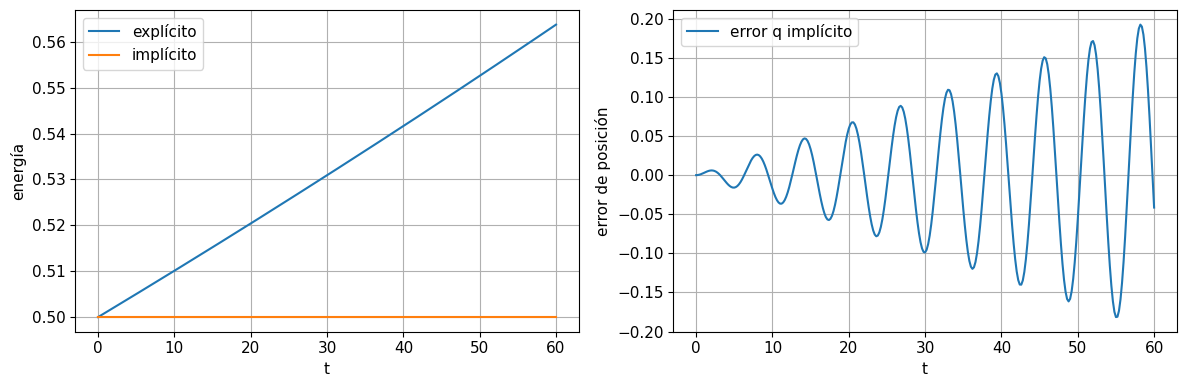

In [6]:
A=np.array([[0.,1.],[-1.,0.]]); h=0.2; n=300
t=np.arange(n+1)*h
implicit=np.empty((n+1,2)); implicit[0]=[1.,0.]
M=np.linalg.solve(np.eye(2)-h*A/2,np.eye(2)+h*A/2)
for j in range(n): implicit[j+1]=M@implicit[j]
_,explicit=midpoint(lambda t,y:A@y,(0,n*h),[1.,0.],n)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(t,0.5*np.sum(explicit**2,axis=1),label="explícito")
ax[0].plot(t,0.5*np.sum(implicit**2,axis=1),label="implícito")
ax[0].set(xlabel="t",ylabel="energía"); ax[0].legend()
ax[1].plot(t,implicit[:,0]-np.cos(t),label="error q implícito")
ax[1].set(xlabel="t",ylabel="error de posición"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretación.** El implícito conserva energía de este oscilador lineal, pero muestra error de fase. Conservar una invariante no implica representar exactamente la trayectoria. En sistemas generales, ser simpléctico tampoco significa conservar exactamente toda energía.

## 7. Región de estabilidad del explícito

Para la ecuación de prueba, $R(z)=1+z+z^2/2$, igual que Heun. El eje real negativo tiene intervalo estable $-2<z<0$. Su mayor precisión respecto a Euler no elimina la limitación de paso para sistemas rígidos.

Podemos dibujar $|R(z)|=1$ en el plano complejo: un autovalor $\lambda$ debe quedar dentro tras multiplicarlo por $h$. Este criterio es directo para sistemas lineales normales; en matrices no normales puede haber crecimiento transitorio adicional.

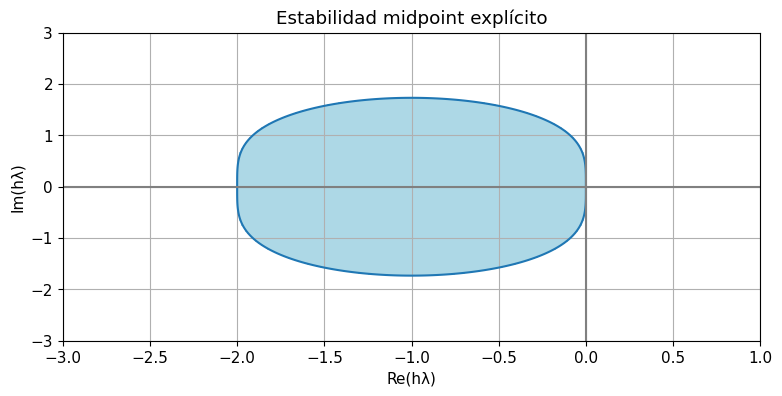

In [7]:
re=np.linspace(-3,1,350); im=np.linspace(-3,3,350)
Z=re[None,:]+1j*im[:,None]; R=1+Z+Z**2/2
plt.contourf(re,im,abs(R)<=1,levels=[-0.5,0.5,1.5],colors=["white","lightblue"])
plt.contour(re,im,abs(R),levels=[1],colors="tab:blue")
plt.axhline(0,color="gray"); plt.axvline(0,color="gray")
plt.xlabel("Re(hλ)"); plt.ylabel("Im(hλ)"); plt.title("Estabilidad midpoint explícito")
plt.show()

**Interpretación.** Los puntos azulados representan la región de módulo no mayor que uno. El eje imaginario queda fuera salvo el origen, lo que explica la deriva del oscilador explícito.

## 8. Un modelo logístico

Para $y'=r y(1-y/K)$, los equilibrios son $0$ y $K$. Si $0<y_0<K$, la solución exacta crece hacia $K$ y permanece en ese intervalo. El orden dos no garantiza esa región invariante con cualquier paso.

Estudiar modelos con cotas conocidas permite diagnosticar sobrepasos que un error medio de trayectoria podría esconder.

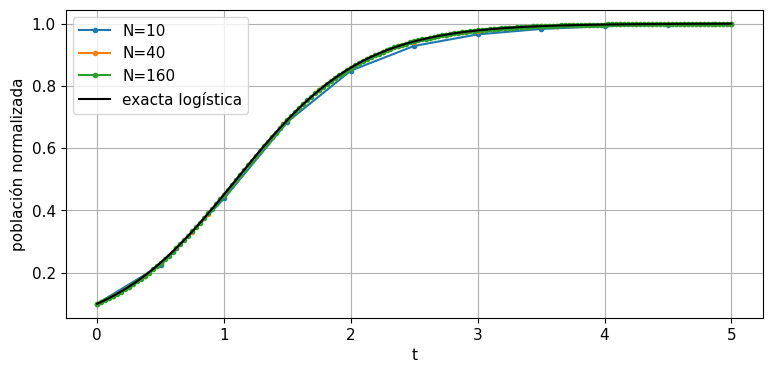

In [8]:
r,K,y0=2.,1.,0.1
q=np.linspace(0,5,500); exact=K/(1+(K/y0-1)*np.exp(-r*q))
for n in [10,40,160]:
    t,y=midpoint(lambda t,y:r*y*(1-y/K),(0,5),y0,n)
    plt.plot(t,y[:,0],"o-",markersize=3,label=f"N={n}")
plt.plot(q,exact,"k",label="exacta logística")
plt.xlabel("t"); plt.ylabel("población normalizada"); plt.legend(); plt.show()

**Interpretación.** Los resultados finos deben acercarse al crecimiento exacto. Prueba un paso todavía mayor y observa si se respetan las cotas; el tamaño admisible depende de la dinámica y del método.

## 9. Elección entre métodos de orden dos

Heun promedia pendientes en extremos predichos; midpoint usa una pendiente en el centro predicho. Ambos cuestan dos evaluaciones y tienen orden dos, pero sus errores no lineales difieren. Ninguno es universalmente más preciso para toda ecuación.

Usa un experimento representativo del problema y del observable. Si conservar estructura geométrica es central, evalúa métodos que la preserven, como el midpoint implícito, en vez de inferir esa propiedad del nombre del algoritmo.

## 10. Convergencia, error y coste: cómo hacer una comparación justa

Si un método tiene orden global $p=2$, en el régimen asintótico se espera $E(h)\approx C h^p$ para problemas suficientemente suaves y un intervalo temporal fijo. El estimador
$$p_{\rm obs}=\log_2\frac{E(h)}{E(h/2)}$$
solo es significativo mientras el error de referencia y el redondeo sean menores que el error medido. Una trayectoria visualmente correcta puede tener error de fase, sesgo en un observable o errores localizados en transitorios.

Para comparar métodos, cuenta evaluaciones de $f$, resoluciones lineales y, en métodos implícitos, iteraciones de Newton. Un método de más orden puede ser más barato para una precisión dada, pero no necesariamente para una tolerancia muy laxa o una función no suave. Si aparecen discontinuidades o eventos, separa los intervalos suaves y localiza el cambio.

Guarda el tiempo final real de cada integración. Usar `int(T/h)` puede terminar antes de $T$ si el cociente no es entero. En estos ejemplos fijamos el número de pasos y calculamos $h=(T-t_0)/N$ para llegar exactamente al extremo. Una malla de salida fija tampoco debe confundirse con los pasos internos de un solver adaptativo.

## 11. De la simulación a SciML

En un problema inverso se ajusta un parámetro $\theta$ minimizando
$$L_h(\theta)=\sum_i\left[y_h(t_i;\theta)-y_i^{\rm obs}\right]^2.$$
El subíndice $h$ recuerda que estamos optimizando la salida de un simulador discretizado. Si el método midpoint explícito genera un sesgo sistemático, el ajuste puede compensarlo con un parámetro equivocado. Repite la inferencia con una malla más fina y observa si el parámetro estimado cambia.

En una Neural ODE, $f_\theta(t,y)$ puede ser una red, pero el solver conserva sus requisitos de regularidad y estabilidad. Reducir la pérdida de entrenamiento no prueba precisión de integración. Para física diferenciable, una derivada del programa discreto es una sensibilidad de ese programa; hace falta verificar que se estabiliza al refinar la discretización.

Define qué observable importa: valor final, energía, evento, amplitud o una norma de trayectoria. No compares únicamente la apariencia de curvas. Una evaluación científica útil separa error de datos, error de modelo y error numérico, porque mejorar uno de ellos no garantiza mejorar los demás.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_2_Heun.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_4_Runge_Kutta.ipynb) |